# Hands-on exercise

In this simple example you are required to perform a simple linear regression with scipy. Find all the information on the function in the documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html

### Assignment

1) Load the provided .csv file with the used car data

2) Use a linear regression to estimate the car prices from the year, kilometers or engine power. You can make a simple 1D regression from each one of the parameters independently (as an optional task you can also try a 2D or 3D regression combining multiple cues)

3) Firstly perform the estimation using the scipy linregress function (or alternatively you can use the sklearn.linear_model.LinearRegression class).
NB: check the documentation of the two methods!! In particular be aware of the number of outputs (in case use "_" to avoid the return of a specific output).

4) Have a look at the correlation coefficient to see which of the 3 features works better

5) Then implement the least square algorithm: you should get exactly the same solution of linregress !

6) Plot the data and the lines representing the output of the linregress and least square algorithms


In [11]:
import matplotlib.pyplot as plt
import csv
import scipy
import numpy as np
import sklearn as sl
from sklearn import linear_model

In [12]:
# Load the provided data file with the used car data (you can also have a look at it with any text editor)

filename = "data/km_year_power_price.csv"
lines = csv.reader(open(filename, newline=''), delimiter=',')

# place your loading code here

dataset = list(lines)[1:]
for i in range(len(dataset)):
    dataset[i] = [float(x) for x in dataset[i]]
#print(dataset)
print('Number of entries:', len(dataset), end='\n\n')
# you can convert lists to numpy for automatic print formatting:
dataset=np.array(dataset)
print(dataset)
km=dataset[:,0]
year=dataset[:,1]
power=dataset[:,2]
avgPrice=dataset[:,3]

Number of entries: 1297

[[1.250000e+05 2.001000e+03 4.000000e+01 1.371110e+03]
 [1.500000e+05 2.001000e+03 4.000000e+01 1.298700e+03]
 [5.000000e+03 2.001000e+03 6.000000e+01 1.232430e+03]
 ...
 [2.000000e+04 2.015000e+03 2.600000e+02 4.949238e+04]
 [1.000000e+04 2.015000e+03 3.000000e+02 3.854269e+04]
 [2.000000e+04 2.015000e+03 3.000000e+02 3.968332e+04]]


Use linear regression to estimate the car prices from the year, kilometers or engine power. 
You can make a simple 1D regression from each one of the parameters independently 




In [3]:
# linear regression with linregress (estimate price from year)

# your code.....
result_km = scipy.stats.linregress(km,avgPrice)
print (result_km.slope)
print (result_km.intercept)
result_year = scipy.stats.linregress(year,avgPrice)
print (result_year.slope)
print (result_year.intercept)
result_power = scipy.stats.linregress(power,avgPrice)
print (result_power.slope)
print (result_power.intercept)

-0.0542515133097257
16692.34530251974
1509.09382533522
-3018309.4849569555
90.33080718820226
-1303.912698987986


In [29]:
# (Optional) linear regression with linear_model.LinearRegression() (estimate price from year)
# Recall that in Python a mx1 matrix is different from a 1D array -> need to reshape

# your code.....
X = year.reshape(-1, 1) 
y = avgPrice
model = linear_model.LinearRegression()
model.fit(X, y)

print(f"Coefficient(slope): {model.coef_}")
print(f"Intercept: {model.intercept_}")
print(f"Difference from liregress: {model.coef_[0]-result_year.slope}")
print(f"Difference from liregress: {model.intercept_-result_year.intercept}")

Coefficient(slope): [1509.09382534]
Intercept: -3018309.4849569555
Difference from liregress: 0.0
Difference from liregress: 0.0


In [5]:
# (Optional) perform linear regression with a manually implemented least squares (estimate price from year)
# You should get exactly the same solution of linregress !

# your code.....
x = year
y = avgPrice
x_mean = np.mean(x)
y_mean = np.mean(y)

# 2. Calcoliamo numeratore e denominatore della formula di m
numerator = np.sum((x - x_mean) * (y - y_mean))
denominator = np.sum((x - x_mean) ** 2)

# 3. Troviamo pendenza (m) e intercetta (q)
m_manuale = numeratore / denominatore
q_manuale = y_mean - (m_manuale * x_mean)

print("--- Risultati 1D a mano ---")
print(f"Pendenza (m): {m_manuale}")
print(f"Intercetta (q): {q_manuale}")

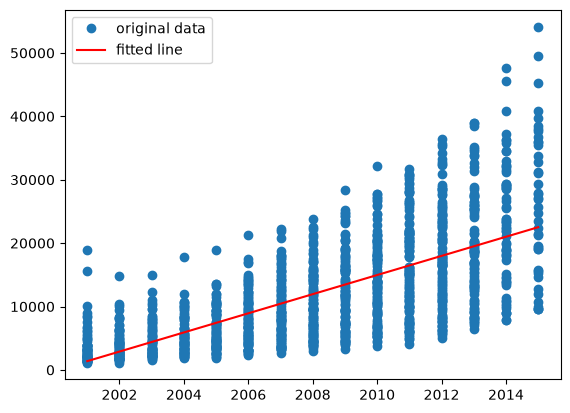

In [16]:
# Plot the data and the lines representing the output of the linregress and least square algorithms

# your code....
plt.plot(year, avgPrice, 'o', label='original data')
plt.plot(year, result_year.intercept + result_year.slope*year, 'r', label='fitted line')
plt.legend()
plt.show()


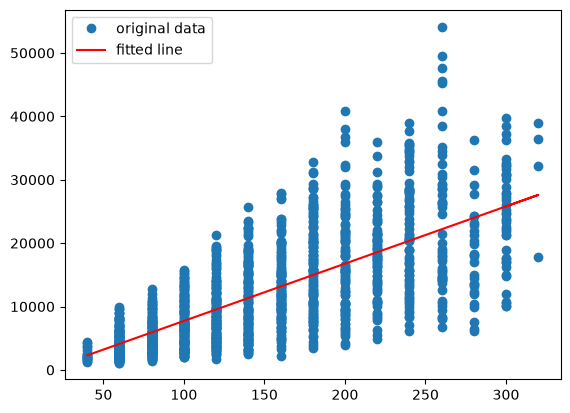

In [19]:
# linear regression with linregress (estimate price from power)

# your code.....
plt.plot(power, avgPrice, 'o', label='original data')
plt.plot(power, result_power.intercept + result_power.slope*power, 'r', label='fitted line')
plt.legend()
plt.show()

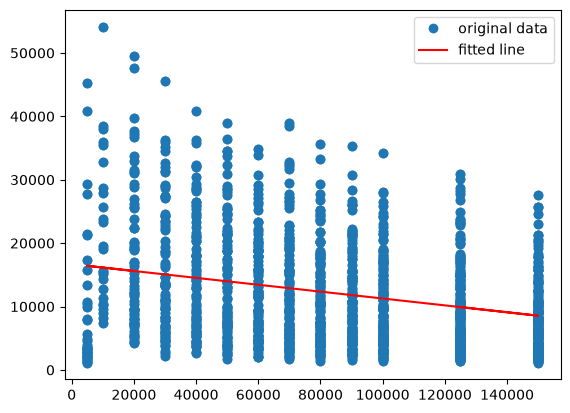

In [15]:
# linear regression with linregress (estimate price from km)

# your code...
plt.plot(km, avgPrice, 'o', label='original data')
plt.plot(km, result_km.intercept + result_km.slope*km, 'r', label='fitted line')
plt.legend()
plt.show()

In [20]:
# Have a look at the correlation coefficients to see which of the 3 features works better

# your code......
print(result_year.rvalue)
print(result_power.rvalue)
print(result_km.rvalue)

0.6767043169095439
0.7085500315263966
-0.25728674299884985


--- Risultati Regressione Lineare Multipla ---
Coefficienti (uno per l'anno, uno per la potenza): [1325.2284004    80.43004469]
Intercetta: -2661196.79


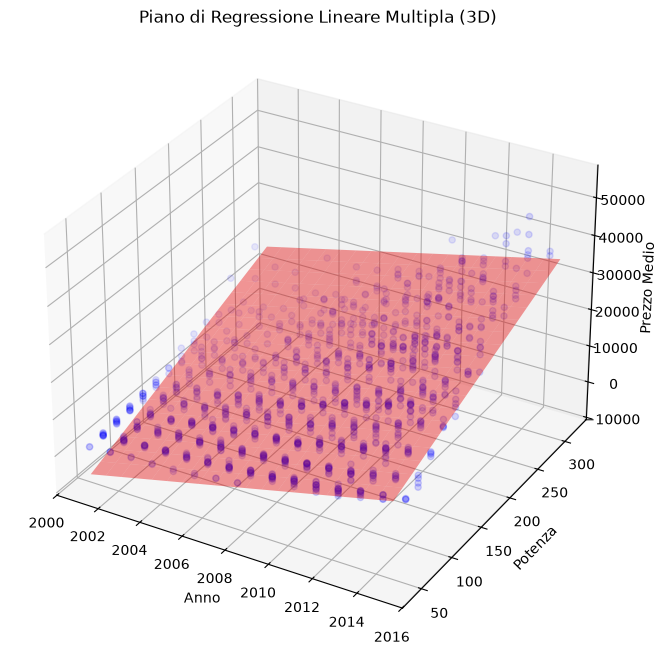

In [34]:
# (Optional) 2D linear regression with linear model (estimate price from year and power)


# your code......
X = dataset[:, [1, 2]]
y = avgPrice           
model = linear_model.LinearRegression()
model.fit(X, y)

# Stampiamo i risultati
print("--- Risultati Regressione Lineare Multipla ---")
print(f"Coefficienti (uno per l'anno, uno per la potenza): {model.coef_}")
print(f"Intercetta: {model.intercept_:.2f}")

# Creiamo la figura 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

# 1. Disegniamo i punti reali delle auto nello spazio 3D
ax.scatter(year, power, avgPrice, color='blue', alpha=0.4, label='Dati reali')

# 2. Creiamo una griglia di valori per disegnare il piano di regressione
xx, yy = np.meshgrid(
    np.linspace(year.min(), year.max(), 20),
    np.linspace(power.min(), power.max(), 20)
)
# Calcoliamo l'altezza z (il prezzo stimato dal piano) per ogni punto della griglia
zz = model.intercept_ + model.coef_[0] * xx + model.coef_[1] * yy

# 3. Disegniamo il piano
ax.plot_surface(xx, yy, zz, color='red', alpha=0.4, edgecolor='none')

ax.set_xlabel('Anno')
ax.set_ylabel('Potenza')
ax.set_zlabel('Prezzo Medio')
ax.set_title('Piano di Regressione Lineare Multipla (3D)')

plt.show()

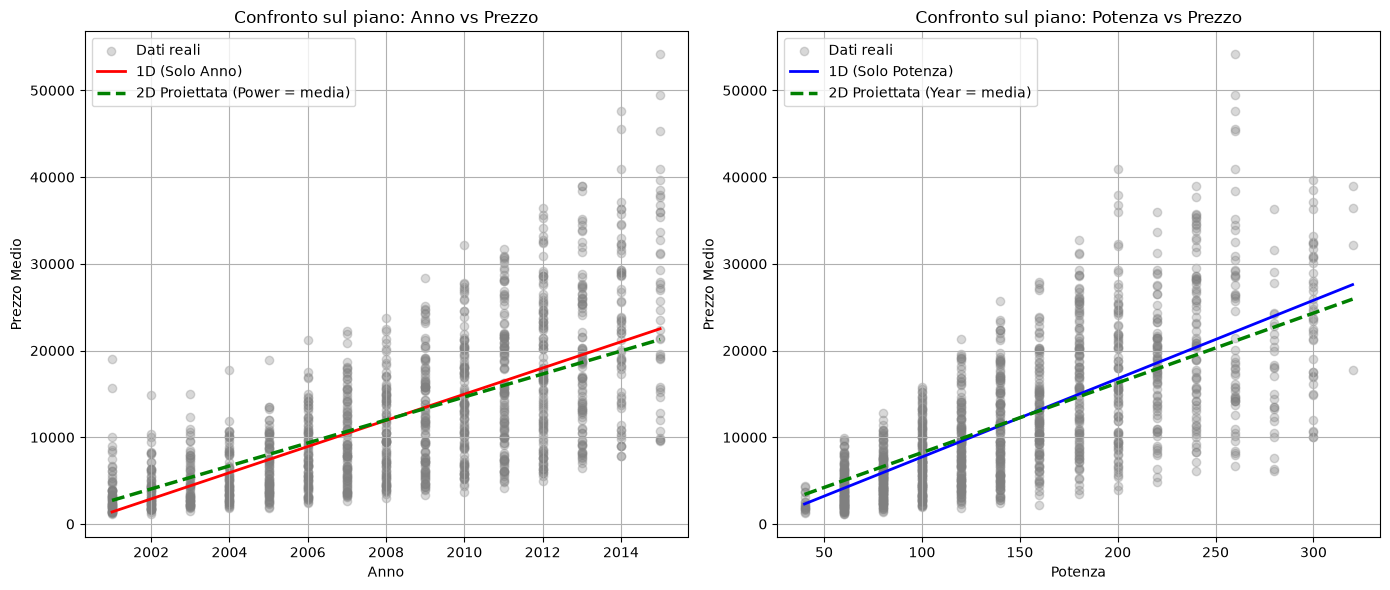

In [35]:
# --- 1. REGRESSIONI 1D (SciPy) ---
result_year = scipy.stats.linregress(year, avgPrice)
result_power = scipy.stats.linregress(power, avgPrice)

# --- 2. REGRESSIONE MULTIPLA 2D (Scikit-learn) ---
X = dataset[:, [1, 2]]  # [Anno, Potenza]
y = avgPrice            
model = linear_model.LinearRegression()
model.fit(X, y)

# --- 3. PROIEZIONI DEL MODELLO 2D SUI SINGOLI PIANI ---
mean_power = np.mean(power)
mean_year = np.mean(year)

# Proiezione sul piano (Anno vs Prezzo): teniamo la Potenza fissa alla media
line_2d_on_year = model.intercept_ + model.coef_[0] * year + model.coef_[1] * mean_power

# Proiezione sul piano (Potenza vs Prezzo): teniamo l'Anno fisso alla media
line_2d_on_power = model.intercept_ + model.coef_[0] * mean_year + model.coef_[1] * power

# Ordinamenti per evitare linee spezzate nei grafici
idx_year = np.argsort(year)
idx_power = np.argsort(power)

# --- 4. CREAZIONE DEI DUE SUBPLOTS ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- GRAFICO 1: Anno vs Prezzo ---
ax1.scatter(year, avgPrice, color='gray', alpha=0.3, label='Dati reali')
ax1.plot(year[idx_year], result_year.intercept + result_year.slope * year[idx_year], 
         color='red', linewidth=2, label='1D (Solo Anno)')
ax1.plot(year[idx_year], line_2d_on_year[idx_year], 
         color='green', linestyle='--', linewidth=2.5, label='2D Proiettata (Power = media)')
ax1.set_xlabel('Anno')
ax1.set_ylabel('Prezzo Medio')
ax1.set_title('Confronto sul piano: Anno vs Prezzo')
ax1.legend()
ax1.grid(True)

# --- GRAFICO 2: Potenza vs Prezzo ---
ax2.scatter(power, avgPrice, color='gray', alpha=0.3, label='Dati reali')
ax2.plot(power[idx_power], result_power.intercept + result_power.slope * power[idx_power], 
         color='blue', linewidth=2, label='1D (Solo Potenza)')
ax2.plot(power[idx_power], line_2d_on_power[idx_power], 
         color='green', linestyle='--', linewidth=2.5, label='2D Proiettata (Year = media)')
ax2.set_xlabel('Potenza')
ax2.set_ylabel('Prezzo Medio')
ax2.set_title('Confronto sul piano: Potenza vs Prezzo')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()